# Varying-demand experiment

This notebook conducts varying-demand experiment, where consider a demand pattern based on 2025 CAISO hourly load, rescales demand to $[0.1,4]$, preserves the chronological daily pattern, and adds local smooth random perturbations to generate repeated trials and confidence intervals.


In [1]:
import numpy as np
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from numba import jit, njit

## Load and prepare CAISO 2025 hourly demand

This cell first looks for the combined CSV created earlier. If it is not present, it tries to reconstruct the 2025 panel from monthly CAISO Excel files in the working directory.


In [2]:
import math
from pathlib import Path
import pandas as pd

caiso_2025 = pd.read_csv('caiso_hourly_load_2025_combined.csv')

print(f"Loaded {len(caiso_2025)} hourly observations.")
print(f"Date range: {caiso_2025['timestamp'].min()} to {caiso_2025['timestamp'].max()}")
print(f"Scaled demand range: [{caiso_2025['scaled_demand'].min():.3f}, {caiso_2025['scaled_demand'].max():.3f}]")

caiso_2025.head()

Loaded 8760 hourly observations.
Date range: 2025-01-01 00:00:00 to 2025-12-31 23:00:00
Scaled demand range: [0.100, 4.000]


,Date,HR,CAISO,timestamp,scaled_demand
0,2025-01-01,1,21768.585137,2025-01-01 00:00:00,0.890375
1,2025-01-01,2,21111.893379,2025-01-01 01:00:00,0.798200
2,2025-01-01,3,20358.821469,2025-01-01 02:00:00,0.692497
3,2025-01-01,4,19926.846964,2025-01-01 03:00:00,0.631864
4,2025-01-01,5,19916.727203,2025-01-01 04:00:00,0.630444


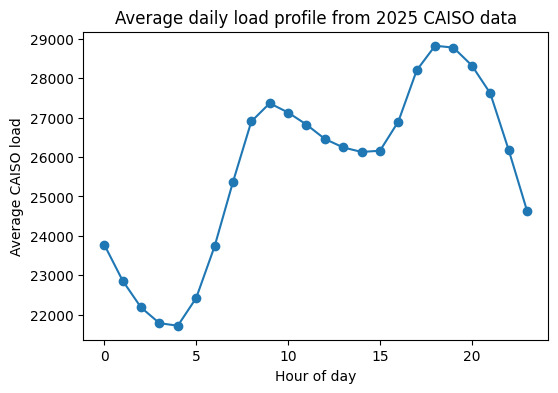

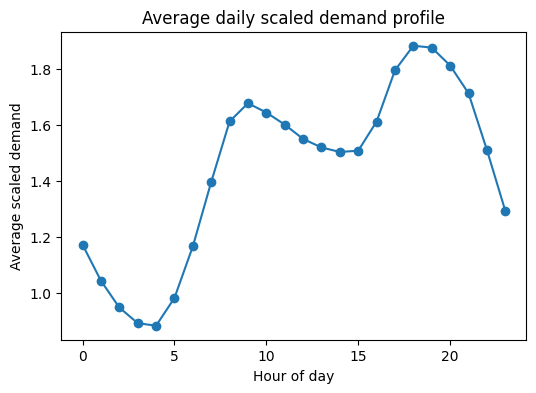

In [3]:
caiso_2025["timestamp"] = pd.to_datetime(caiso_2025["timestamp"], errors="coerce")


avg_daily_profile = (
    caiso_2025.assign(hour_of_day=caiso_2025['timestamp'].dt.hour)
    .groupby('hour_of_day')[['CAISO', 'scaled_demand']]
    .mean()
    .reset_index()
)

plt.figure(figsize=(6, 4))
plt.plot(avg_daily_profile['hour_of_day'], avg_daily_profile['CAISO'], marker='o')
plt.xlabel('Hour of day')
plt.ylabel('Average CAISO load')
plt.title('Average daily load profile from 2025 CAISO data')
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(avg_daily_profile['hour_of_day'], avg_daily_profile['scaled_demand'], marker='o')
plt.xlabel('Hour of day')
plt.ylabel('Average scaled demand')
plt.title('Average daily scaled demand profile')
plt.show()

In [4]:
# Problem setup

cost_type = 'log'

d_min = 0.1
d_max = 4.0

T_range = 2**np.arange(14,24,1) - 2
num_instances = 10

### Piecewise quadratic cost

We consider a single supplier with a smooth, piecewise quadratic cost function parameterized as follows:

$$
C(x) = 
\begin{cases}
\alpha x^2 + 10\alpha x & \text{if } 0 \le x < 1; \\
2\alpha x^2 + 8\alpha x + \alpha & \text{if } 1 \le x < 2; \\
4\alpha x^2 + 9 \alpha & \text{if } 2 \le x < 4.
\end{cases}
$$

Then, the supply function at price $p$ is
$$
x^\star(p) = 
\begin{cases}
0 & \text{if } 0 \le p < 10\alpha; \\
\frac{p-10\alpha}{2\alpha} & \text{if } 10\alpha \le p < 12\alpha; \\
\frac{p-8\alpha}{4\alpha} & \text{if } 12\alpha \le p < 16\alpha; \\
\frac{p}{8\alpha} & \text{otherwise}.
\end{cases}
$$

In [5]:
def sample_param_piecewise(rng):
    return rng.uniform(1/128, 1/32)

@jit
def reported_cost_piecewise(x, a):
    if x < 1:
        return a * x**2 + 10*a * x
    elif x < 2:
        return 2*a * x**2 + 8*a * x + a
    else:
        return 4*a * x**2 + 9*a

@jit
def supply_from_price_piecewise(price, a):
    if price < 10*a:
        return 0
    elif price < 12*a:
        return (price - 10*a) / (2*a)
    elif price < 16*a:
        return (price - 8*a) / (4*a)
    else:
        return price / (8*a)

@jit
def optimal_price_piecewise(d, a):
    if d < 1:
        return 2*a * d + 10*a
    elif d < 2:
        return 4*a * d + 8*a
    else:
        return 8*a * d

### Quadratic cost, three suppliers

We consider three suppliers, where the $i$th supplier ($i \in \{1, 2, 3\}$) has a cost function

$$C_i(x) = \alpha_i x^2.$$

Then, the suppliers' supply at price $p$ is

$$ x^*_i(p) = \frac{p}{2\alpha_i}. $$

We sample the cost of each supplier indpendently with $\alpha_i \sim \text{Unif}[1/8, 3/8]$.

In [6]:
def sample_param_multiple(rng):
    return rng.uniform(1/8, 3/8, size=(3,))

@jit
def reported_cost_multiple(x, a):
    u = x / np.sum(1/a)
    ix = u / a
    return np.sum(a * ix**2)

@jit
def supply_from_price_multiple(price, a):
    return price * np.sum(1/a) / 2

@jit
def optimal_price_multiple(d, a):
    return d * 2 / np.sum(1/a)

### Log-barrier-cost single-supplier setup

We consider a **single-supplier** setting using the scalar-parameterized log-barrier reported cost

$$
\hat C(x;\theta) = \theta \log\left(\frac{X}{X-x}\right), \qquad x < X.
$$

For a single supplier with capacity $X$ and parameter $\theta$, the supply at price $p$ is
$$
x^*(p;\theta)=X-\theta/p,
$$
and the demand-clearing price for a realized demand level $d<X$ is
$$
p^*(d)=\theta/(X-d).
$$

We sample the cost function with $\theta \sim \text{Unif}[0.5, 2.0]$.


In [7]:
def sample_param_log(rng):
    return rng.uniform(0.5, 2.0)

X = 6.0            # must stay strictly above the largest scaled demand (4.0 here)
assert X > d_max, 'Need X > d_max so the log cost is finite on the full demand support.'

@jit
def reported_cost_log(x, theta, eps=1e-10):
    x = max(0.0, min(x, X - eps))
    return theta * np.log(X / (X - x))

@jit
def supply_from_price_log(price, theta, eps=1e-10):
    price = max(float(price), eps)
    x = X - theta / price
    return max(0.0, min(x, X - eps))

@jit
def optimal_price_log(d, theta, eps=1e-10):
    d = max(0.0, min(d, X - eps))
    return theta / (X - d)

In [8]:
if cost_type == 'piecewise':
    sample_param = sample_param_piecewise
    reported_cost = reported_cost_piecewise
    supply_from_price = supply_from_price_piecewise
    optimal_price = optimal_price_piecewise
elif cost_type == 'three':
    sample_param = sample_param_multiple
    reported_cost = reported_cost_multiple
    supply_from_price = supply_from_price_multiple
    optimal_price = optimal_price_multiple
elif cost_type == 'log':
    sample_param = sample_param_log
    reported_cost = reported_cost_log
    supply_from_price = supply_from_price_log
    optimal_price = optimal_price_log
else:
    raise ValueError('Unknown cost function type')

In [9]:
@jit
def regret_vary_demand(T, param, d_sequence, d_min=0.1, d_max=4.0):
    # Varying-demand regret computation for the single-supplier log-cost model.
    interval_length = 5 / np.sqrt(T)
    sequence = np.arange(d_min, d_max + interval_length, interval_length)
    if sequence[-1] > d_max:
        sequence = sequence[:-1]
    if sequence[-1] < d_max:
        sequence = np.append(sequence, d_max)

    num_intervals = len(sequence) - 1

    # Initialize price bounds using the demand support rather than piecewise thresholds.
    p_lb_init = 0.0
    p_ub_init = 1.25 * optimal_price(d_max, param)

    p_array = np.full(num_intervals, 0.5 * (p_lb_init + p_ub_init))
    p_lb_array = np.full(num_intervals, p_lb_init)
    p_ub_array = np.full(num_intervals, p_ub_init)

    unified_regret = 0.0
    payment_regret = 0.0
    cost_regret = 0.0
    unmet_demand_regret = 0.0

    for t in range(T):
        d = float(d_sequence[t])
        idx = np.searchsorted(sequence, d, side='right') - 1
        idx = max(0, min(idx, num_intervals - 1))

        p_val = float(p_array[idx])
        supplied = supply_from_price(p_val, param)
        p_star = optimal_price(d, param)

        cost_regret += reported_cost(supplied, param) - reported_cost(d, param)
        unmet_demand_regret += max(d - supplied, 0.0)
        payment_regret += p_val * supplied - p_star * d
        unified_regret += abs(p_val - p_star)

        if supplied < d:
            p_lb_array[idx] = p_val
        else:
            p_ub_array[idx] = p_val
        p_array[idx] = 0.5 * (p_lb_array[idx] + p_ub_array[idx])

    return unified_regret, unmet_demand_regret, cost_regret, payment_regret

@jit
def meta_alg_log(T, param, d_sequence, d_min=0.1, d_max=4.0):
    # Doubling-trick meta algorithm for unknown horizon T.
    unified_regret = 0.0
    unmet_demand_regret = 0.0
    cost_regret = 0.0
    payment_regret = 0.0

    epoch_start = 0
    k = 0
    
    while epoch_start < T:
        epoch_length = min(2**k, T - epoch_start)
        epoch_sequence = d_sequence[epoch_start:epoch_start + epoch_length]

        u_reg, ud_reg, c_reg, p_reg = regret_vary_demand(
            epoch_length,
            param,
            epoch_sequence,
            d_min=d_min,
            d_max=d_max
        )

        unified_regret += u_reg
        unmet_demand_regret += ud_reg
        cost_regret += c_reg
        payment_regret += p_reg

        epoch_start += epoch_length
        k += 1
    
    return unified_regret, unmet_demand_regret, cost_regret, payment_regret

## Run the varying-demand experiment with real CAISO chronology plus local perturbations

This preserves the daily pattern in the 2025 sequence and adds smooth multiplicative noise around each hourly value, rather than resampling hours i.i.d.


In [10]:
def mean_and_ci(arr):
    mean = arr.mean(axis=0)
    sd = arr.std(axis=0, ddof=1)
    se = sd / np.sqrt(arr.shape[0])
    ci_low = mean - 1.96 * se
    ci_high = mean + 1.96 * se
    return mean, ci_low, ci_high

In [11]:
%%time
max_T = max(T_range)

unified_regret_trials = np.zeros((num_instances, len(T_range)))
unmet_demand_regret_trials = np.zeros((num_instances, len(T_range)))
cost_regret_trials = np.zeros((num_instances, len(T_range)))
payment_regret_trials = np.zeros((num_instances, len(T_range)))

rng = np.random.default_rng(0)

real_scaled_demand = caiso_2025["scaled_demand"].to_numpy()
base_sequence = np.resize(real_scaled_demand, max_T)

sigma = 1e-3
kernel = np.array([0.2, 0.6, 0.2])

for trial in range(num_instances):
    raw_noise = rng.normal(0.0, 1, size=max_T)
    smooth_noise = np.convolve(raw_noise, kernel, mode="same")
    
    sampled_sequence = np.clip(
        base_sequence * (1 + sigma * smooth_noise),
        0.1,
        4.0
    )

    param = sample_param(rng)

    for j, T in enumerate(T_range):
        d_sequence = sampled_sequence[:T]

        unified_regret, unmet_demand_regret, cost_regret, payment_regret = meta_alg_log(
            T, param, d_sequence, d_min=0.1, d_max=4.0
        )

        unified_regret_trials[trial, j] = unified_regret
        unmet_demand_regret_trials[trial, j] = unmet_demand_regret
        cost_regret_trials[trial, j] = cost_regret
        payment_regret_trials[trial, j] = payment_regret

CPU times: user 17.6 s, sys: 417 ms, total: 18 s
Wall time: 18 s


In [12]:
if cost_type == 'piecewise':
    plot_name = 'Piecewise quadratic cost, single supplier'
elif cost_type == 'three':
    plot_name = 'Quadratic cost, three suppliers'
elif cost_type == 'log':
    plot_name = 'Log-barrier cost, single supplier'
else:
    raise ValueError('Unknown cost function type')

In [13]:
figsize = (6, 4)
postfix = ''
plt.rcParams.update({'font.size': 11})

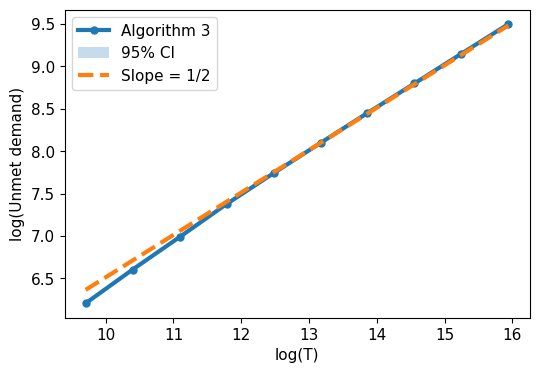

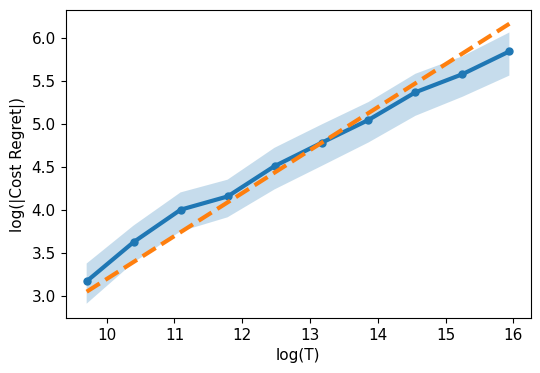

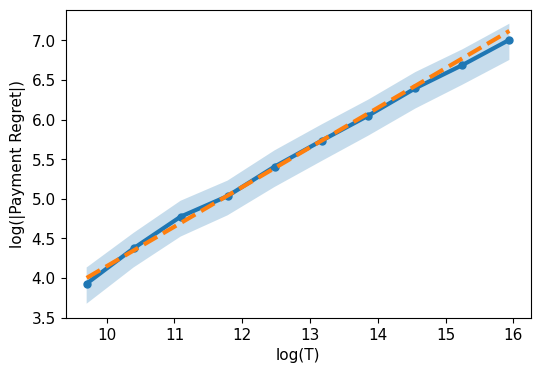

In [14]:
logT = np.log(np.array(T_range))

mid_idx = len(logT) // 2
anchor_T = logT[mid_idx]

# unmet demand
unmet_demand_regret_arr_full, unmet_ci_low, unmet_ci_high = mean_and_ci(unmet_demand_regret_trials)
logR = np.log(np.maximum(unmet_demand_regret_arr_full, 1e-12))
log_ci_low = np.log(np.maximum(unmet_ci_low, 1e-12))
log_ci_high = np.log(np.maximum(unmet_ci_high, 1e-12))
anchor_R = logR[mid_idx]
ref_line = 0.5 * (logT - anchor_T) + anchor_R

plt.figure(figsize=figsize)
plt.plot(logT, logR, marker='o', markersize=5, linewidth=3, label='Algorithm 3')
plt.fill_between(logT, log_ci_low, log_ci_high, alpha=0.25, label='95% CI')
plt.plot(logT, ref_line, '--', linewidth=3, label='Slope = 1/2')
plt.xlabel('log(T)')
plt.ylabel('log(Unmet demand)')
#plt.title(f'{plot_name}: unmet demand')
plt.legend()
plt.savefig(f'{cost_type}_unmet_demand_loglog{postfix}.pdf', bbox_inches='tight')
plt.show()

# cost regret
cost_abs_trials = np.abs(cost_regret_trials)
cost_abs_mean, cost_abs_ci_low, cost_abs_ci_high = mean_and_ci(cost_abs_trials)
logR = np.log(np.maximum(cost_abs_mean, 1e-12))
log_ci_low = np.log(np.maximum(cost_abs_ci_low, 1e-12))
log_ci_high = np.log(np.maximum(cost_abs_ci_high, 1e-12))
anchor_R = logR[mid_idx]
ref_line = 0.5 * (logT - anchor_T) + anchor_R

plt.figure(figsize=figsize)
plt.plot(logT, logR, marker='o', markersize=5, linewidth=3, label='Algorithm 3')
plt.fill_between(logT, log_ci_low, log_ci_high, alpha=0.25, label='95% CI')
plt.plot(logT, ref_line, '--', linewidth=3, label='Slope = 1/2')
plt.xlabel('log(T)')
plt.ylabel('log(|Cost Regret|)')
#plt.legend()
#plt.title(f'{plot_name}: cost regret')
plt.savefig(f'{cost_type}_cost_regret_loglog{postfix}.pdf', bbox_inches='tight')
plt.show()

# Payment regret
payment_abs_trials = np.abs(payment_regret_trials)
payment_abs_mean, payment_abs_ci_low, payment_abs_ci_high = mean_and_ci(payment_abs_trials)
logR = np.log(np.maximum(payment_abs_mean, 1e-12))
log_ci_low = np.log(np.maximum(payment_abs_ci_low, 1e-12))
log_ci_high = np.log(np.maximum(payment_abs_ci_high, 1e-12))
anchor_R = logR[mid_idx]
ref_line = 0.5 * (logT - anchor_T) + anchor_R

plt.figure(figsize=figsize)
plt.plot(logT, logR, marker='o', markersize=5, linewidth=3, label='Algorithm 3')
plt.fill_between(logT, log_ci_low, log_ci_high, alpha=0.25, label='95% CI')
plt.plot(logT, ref_line, '--', linewidth=3, label='Slope = 1/2')
plt.xlabel('log(T)')
plt.ylabel('log(|Payment Regret|)')
#plt.legend()
#plt.title(f'{plot_name}: payment regret')
plt.savefig(f'{cost_type}_payment_regret_loglog{postfix}.pdf', bbox_inches='tight')
plt.show()

In [15]:
unmet_slope = stats.linregress(np.log(T_range), np.log(np.maximum(unmet_demand_regret_arr_full, 1e-12))).slope
cost_slope = stats.linregress(np.log(T_range), np.log(np.maximum(np.abs(cost_abs_mean), 1e-12))).slope
payment_slope = stats.linregress(np.log(T_range), np.log(np.maximum(np.abs(payment_abs_mean), 1e-12))).slope

print('Unmet demand regret slope:', unmet_slope)
print('cost regret slope:', cost_slope)
print('Payment regret slope:', payment_slope)

Unmet demand regret slope: 0.5255566245315685
cost regret slope: 0.41570054961076425
Payment regret slope: 0.4843040653676104
